# Exercice 1 - Régression : prédiction du tarif d'un trajet Uber

**Module** : Technologies IA - ENSA Fès - ILIA2
**Objectif** : prédire `fare_amount` à partir de la distance, de l'heure et du jour de la semaine.

> Jeu de données : [Uber Fares Dataset (Kaggle)](https://www.kaggle.com/datasets/yasserh/uber-fares-dataset) -> placer `uber.csv` dans le dossier `data/`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

## Étape 1 - Chargement et exploration

In [2]:
data = pd.read_csv("../data/uber.csv")
print(data.head())
print(data.info())
print(data.isnull().sum())
data.describe()

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,2.000000e+05,200000.000000,200000.000000,200000.000000,199999.000000,199999.000000,200000.000000
mean,2.771250e+07,11.359955,-72.527638,39.935885,-72.525292,39.923890,1.684535
std,1.601382e+07,9.901776,11.437787,7.720539,13.117408,6.794829,1.385997
min,1.000000e+00,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,1.382535e+07,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,2.774550e+07,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,4.155530e+07,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,5.542357e+07,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


**Observations à noter dans votre compte rendu** :
- Quelles colonnes ont des valeurs manquantes ? (en général `dropoff_longitude/latitude`, 1 ligne)
- Quels types de variables ? (`pickup_datetime` est une chaîne de caractères)
- Valeurs aberrantes visibles dans `describe()` (tarifs négatifs, coordonnées à 0, `passenger_count` = 0 ou très grand).

## Étape 2 - Nettoyage et préparation

⚠️ **Piège du TP** : le fichier Kaggle **ne contient pas de colonne `distance`**. Il faut la calculer
à partir des coordonnées GPS avec la **formule de Haversine**.

In [3]:
# colonnes inutiles
data = data.drop(columns=[c for c in ["Unnamed: 0", "key"] if c in data.columns])

# valeurs manquantes
data = data.dropna()

# valeurs aberrantes
data = data[data["fare_amount"] > 0]
data = data[data["passenger_count"].between(1, 6)]
data = data[data["pickup_latitude"].between(-90, 90) & data["dropoff_latitude"].between(-90, 90)]
data = data[data["pickup_longitude"].between(-180, 180) & data["dropoff_longitude"].between(-180, 180)]
data = data[(data["pickup_longitude"] != 0) & (data["dropoff_longitude"] != 0)]


def haversine(lat1, lon1, lat2, lon2):
    """Distance en km entre deux points GPS."""
    R = 6371
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))


data["distance"] = haversine(
    data["pickup_latitude"], data["pickup_longitude"],
    data["dropoff_latitude"], data["dropoff_longitude"],
)
# trajets de distance nulle ou irréalistes
data = data[(data["distance"] > 0) & (data["distance"] < 100)]

# variables dérivées
data["pickup_datetime"] = pd.to_datetime(data["pickup_datetime"])
data["hour"] = data["pickup_datetime"].dt.hour
data["day_of_week"] = data["pickup_datetime"].dt.dayofweek

print(data.shape)
data[["fare_amount", "distance", "hour", "day_of_week"]].describe()

(193191, 10)


,fare_amount,distance,hour,day_of_week
count,193191.000000,193191.000000,193191.000000,193191.000000
mean,11.354570,3.362822,13.488869,3.050018
std,9.740401,3.730419,6.516374,1.946473
min,0.010000,0.000084,0.000000,0.000000
25%,6.000000,1.280083,9.000000,1.000000
50%,8.500000,2.180317,14.000000,3.000000
75%,12.500000,3.939281,19.000000,5.000000
max,499.000000,99.162509,23.000000,6.000000


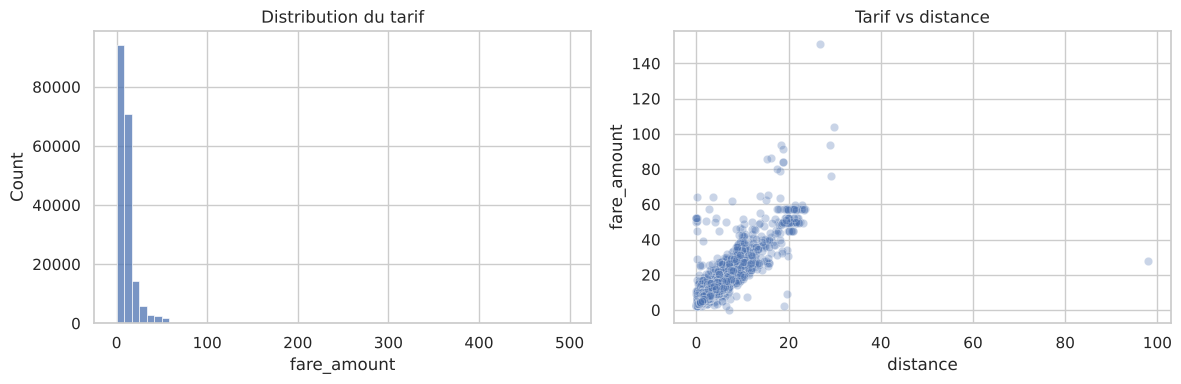

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data["fare_amount"], bins=60, ax=ax[0]).set_title("Distribution du tarif")
sns.scatterplot(data=data.sample(5000, random_state=42), x="distance", y="fare_amount", alpha=0.3, ax=ax[1]).set_title("Tarif vs distance")
plt.tight_layout()
plt.show()

## Étape 3 - Séparation des données

In [5]:
X = data[["distance", "hour", "day_of_week"]]
y = data["fare_amount"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(154552, 3) (38639, 3)


## Étape 4 - Entraînement : régression linéaire

In [6]:
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

print("Coefficients :", dict(zip(X.columns, lr.coef_.round(4))))
print("Intercept    :", round(lr.intercept_, 4))

Coefficients : {'distance': np.float64(2.1876), 'hour': np.float64(0.0068), 'day_of_week': np.float64(-0.0413)}
Intercept    : 4.0218


## Étape 5 - Évaluation

In [7]:
def evaluate(name, y_true, y_hat):
    mae = mean_absolute_error(y_true, y_hat)
    rmse = np.sqrt(mean_squared_error(y_true, y_hat))
    r2 = r2_score(y_true, y_hat)
    print(f"{name:<20} MAE = {mae:.3f} | RMSE = {rmse:.3f} | R2 = {r2:.3f}")
    return {"Modèle": name, "MAE": mae, "RMSE": rmse, "R2": r2}


res_lr = evaluate("Régression linéaire", y_test, y_pred)

Régression linéaire  MAE = 2.446 | RMSE = 5.605 | R2 = 0.686


## Étape 6 - Amélioration avec Random Forest

In [8]:
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

res_rf = evaluate("Random Forest", y_test, y_pred_rf)
pd.DataFrame([res_lr, res_rf]).set_index("Modèle").round(3)

Random Forest        MAE = 2.529 | RMSE = 5.384 | R2 = 0.710


,MAE,RMSE,R2
Modèle,,,
Régression linéaire,2.446,5.605,0.686
Random Forest,2.529,5.384,0.710


## Étape 7 - Visualisation des résultats

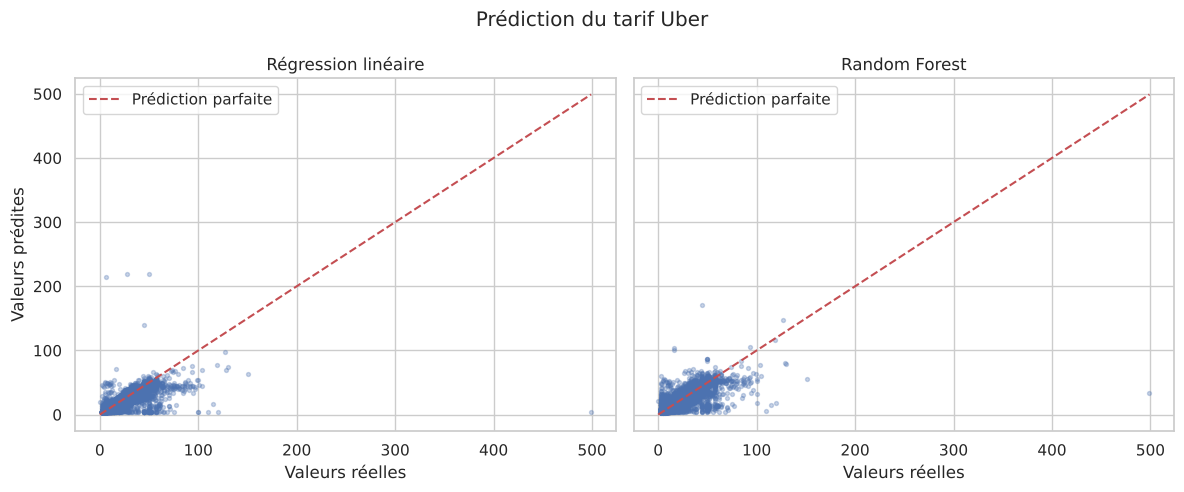

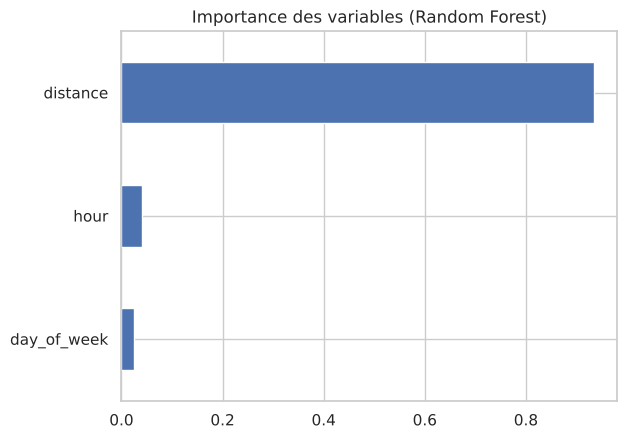

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for a, pred, title in zip(ax, [y_pred, y_pred_rf], ["Régression linéaire", "Random Forest"]):
    a.scatter(y_test, pred, alpha=0.3, s=8)
    lim = [0, max(y_test.max(), pred.max())]
    a.plot(lim, lim, "r--", label="Prédiction parfaite")
    a.set_xlabel("Valeurs réelles")
    a.set_title(title)
    a.legend()
ax[0].set_ylabel("Valeurs prédites")
plt.suptitle("Prédiction du tarif Uber")
plt.tight_layout()
plt.show()

pd.Series(rf.feature_importances_, index=X.columns).sort_values().plot.barh(title="Importance des variables (Random Forest)")
plt.show()

## Conclusion (à rédiger avec vos propres chiffres)

- Quel modèle obtient le meilleur RMSE / R² ? De combien ?
- Quelle variable est la plus importante ? (attendu : `distance`)
- Limites : `hour` et `day_of_week` sont des variables **cycliques** ; les coordonnées brutes (quartiers, aéroports) ne sont pas exploitées ; présence d'outliers de tarif.
- Pistes : ajouter lat/long, `month`, `year` (les tarifs ont évolué avec le temps), essayer `GradientBoostingRegressor`.